# BTC/USDT 6-Hour-Ahead (12-Bar) Direction Prediction

Predict whether the **open price 12 bars ahead (6 hours later)** will be
higher or lower than the **current bar's open price**, and by how many
percent, using a LightGBM model trained on engineered technical features
from the 30-minute BTC/USDT bar data.

This is the same pipeline as the 1-bar-ahead notebook (`model.ipynb`), with
the forecast horizon extended from 1 bar (30 minutes) to 12 bars (6 hours).

**Target**
- `y_cls`: 1 if `open[t+12] > open[t]`, else 0 (binary direction)
- `y_reg`: `(open[t+12] - open[t]) / open[t] * 100` (signed percent move over the next 12 bars)

**Leakage guard**: the target window `[t, t+12]` starts with bar `t`'s own
price action (since `open[t+1]` is essentially bar `t`'s close), so features
used to predict it are still built from data available **through bar
`t-1`** only (the feature matrix is shifted forward by one bar relative to
the target) — no information from bar `t` or later ever reaches the model.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
# from sklearn.model_selection import TimeSeriesSplit
# from sklearn.metrics import (
#     roc_auc_score, roc_curve, precision_score, recall_score, f1_score,
#     confusion_matrix, classification_report, mean_absolute_error, mean_squared_error,
# )

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [3]:
dataset_lag1 = pd.read_csv("./data/processed_dataset_target_lag1.csv", index_col=0)
dataset_lag6 = pd.read_csv("./data/processed_dataset_target_lag6.csv", index_col=0)
dataset_lag12 = pd.read_csv("./data/processed_dataset_target_lag12.csv", index_col=0)

In [4]:
feature_cols = [col for col in dataset_lag1.columns if col not in ("y_reg")]

## 1. Time-based train / validation / test split

Chronological split (no shuffling) — 70% train / 15% validation / 15% test —
since shuffling would leak future information into training for a time series.

In [5]:
X = dataset_lag12[feature_cols]
# y_cls = dataset_lag12["y_cls"]
y_reg = dataset_lag12["y_reg"]

n = len(dataset_lag12)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, X_val, X_test = X.iloc[:train_end], X.iloc[train_end:val_end], X.iloc[val_end:]
# yc_train, yc_val, yc_test = y_cls.iloc[:train_end], y_cls.iloc[train_end:val_end], y_cls.iloc[val_end:]
yr_train, yr_val, yr_test = y_reg.iloc[:train_end], y_reg.iloc[train_end:val_end], y_reg.iloc[val_end:]

print("train:", X_train.shape, dataset_lag12.index[0], "->", dataset_lag12.index[train_end - 1])
print("val:  ", X_val.shape, dataset_lag12.index[train_end], "->", dataset_lag12.index[val_end - 1])
print("test: ", X_test.shape, dataset_lag12.index[val_end], "->", dataset_lag12.index[-1])

train: (36677, 72) 2023-09-06 04:00:00+00:00 -> 2025-10-09 06:00:00+00:00
val:   (7859, 72) 2025-10-09 06:30:00+00:00 -> 2026-03-21 23:30:00+00:00
test:  (7860, 72) 2026-03-22 00:00:00+00:00 -> 2026-09-01 17:30:00+00:00


In [6]:
yr_train

bar_open_time_utc
2023-09-06 04:00:00+00:00   -0.114068
2023-09-06 04:30:00+00:00   -0.102529
2023-09-06 05:00:00+00:00   -0.110540
2023-09-06 05:30:00+00:00    0.020343
2023-09-06 06:00:00+00:00   -0.051541
                               ...   
2025-10-09 04:00:00+00:00   -0.184344
2025-10-09 04:30:00+00:00   -0.408970
2025-10-09 05:00:00+00:00    0.020926
2025-10-09 05:30:00+00:00    0.549716
2025-10-09 06:00:00+00:00    0.521405
Name: y_reg, Length: 36677, dtype: float64

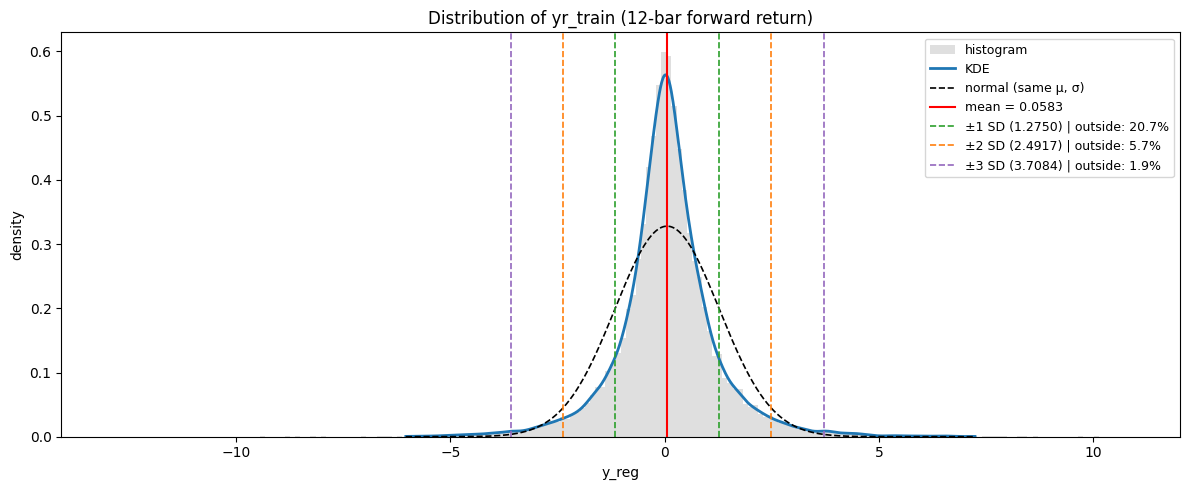

P(y > +1 SD) = 10.35%   (normal would give 15.87%)
P(y > +1 SD from 0, i.e. your label threshold) = 11.17%


In [7]:
from scipy.stats import gaussian_kde, norm

y = yr_train.dropna().values
mu, sd = y.mean(), y.std()

xs = np.linspace(np.percentile(y, 0.1), np.percentile(y, 99.9), 1000)
kde = gaussian_kde(y)

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(y, bins=200, density=True, alpha=0.25, color="gray", label="histogram")
ax.plot(xs, kde(xs), lw=2, label="KDE")
ax.plot(xs, norm.pdf(xs, mu, sd), "--", lw=1.2, color="black", label="normal (same μ, σ)")

ax.axvline(mu, color="red", lw=1.5, label=f"mean = {mu:.4f}")
colors = {1: "tab:green", 2: "tab:orange", 3: "tab:purple"}
for k, c in colors.items():
    share = ((y > mu + k * sd) | (y < mu - k * sd)).mean()
    ax.axvline(mu + k * sd, color=c, ls="--", lw=1.2,
               label=f"±{k} SD ({mu + k*sd:.4f}) | outside: {share:.1%}")
    ax.axvline(mu - k * sd, color=c, ls="--", lw=1.2)

ax.set(title="Distribution of yr_train (12-bar forward return)",
       xlabel="y_reg", ylabel="density")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"P(y > +1 SD) = {(y > mu + sd).mean():.2%}   (normal would give 15.87%)")
print(f"P(y > +1 SD from 0, i.e. your label threshold) = {(y > sd).mean():.2%}")

## 8. Magnitude regression

A second LightGBM regressor predicts the signed percent move itself
(`y_reg`), so predictions can be reported as "up/down by X% over the next
12 bars" rather than direction alone. Compared against a naive
baseline that always predicts 0%.

In [8]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    classification_report, confusion_matrix,
)
from sklearn.calibration import calibration_curve

HORIZON = 12  # bars in the target window [t, t+12]

# Threshold from TRAIN only, so val/test stats never leak into the label
sd = yr_train.std()
thr = sd  # "goes up by more than 1 SD"

yc_train = (yr_train > thr).astype(int)
yc_val   = (yr_val   > thr).astype(int)
yc_test  = (yr_test  > thr).astype(int)

# # Purge: the last HORIZON rows of train/val have target windows that
# # run into the next split, so drop them
# X_tr, y_tr = X_train.iloc[:-HORIZON], yc_train.iloc[:-HORIZON]
# X_va, y_va = X_val.iloc[:-HORIZON],   yc_val.iloc[:-HORIZON]

print(f"threshold (1 SD of train y_reg) = {thr:.5f}")
for name, y in [("train", yc_train), ("val", yc_val), ("test", yc_test)]:
    print(f"{name:5s} positive rate: {y.mean():.2%}  (n={len(y)})")

threshold (1 SD of train y_reg) = 1.21674
train positive rate: 11.17%  (n=36677)
val   positive rate: 11.90%  (n=7859)
test  positive rate: 7.77%  (n=7860)


In [9]:
clf = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=5000,
    learning_rate=0.02,
    num_leaves=31,
    min_child_samples=200,   # large leaves, since financial data is noisy
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    verbose=-1,
)

clf.fit(
    X_train, yc_train,
    eval_set=[(X_val, yc_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(200), lgb.log_evaluation(200)],
)
print("best iteration:", clf.best_iteration_)

Training until validation scores don't improve for 200 rounds
[200]	valid_0's auc: 0.668281	valid_0's binary_logloss: 0.348915
Early stopping, best iteration is:
[95]	valid_0's auc: 0.668507	valid_0's binary_logloss: 0.344863
best iteration: 95


In [10]:
p_val  = clf.predict_proba(X_val)[:, 1]
p_test = clf.predict_proba(X_test)[:, 1]

for name, y, p in [("val", yc_val, p_val), ("test", yc_test, p_test)]:
    print(f"{name:5s} ROC-AUC {roc_auc_score(y, p):.4f} | "
          f"PR-AUC {average_precision_score(y, p):.4f} | "
          f"baseline (pos rate) {y.mean():.4f}")

# Pick the decision threshold on VAL, then apply it to test unchanged
grid = np.linspace(0.02, 0.9, 89)
f1s = [f1_score(yc_val, (p_val >= t).astype(int), zero_division=0) for t in grid]
best_t = grid[int(np.argmax(f1s))]
print(f"\ndecision threshold (max F1 on val): {best_t:.2f}")

pred_test = (p_test >= best_t).astype(int)
print(classification_report(yc_test, pred_test, digits=3, zero_division=0))
print(confusion_matrix(yc_test, pred_test))

# Hit rate by predicted-probability decile on test (the useful view for trading)
dec = pd.qcut(p_test, 10, labels=False, duplicates="drop")
print("\nTest hit rate by probability decile:")
print(pd.Series(yc_test.values).groupby(dec).agg(["mean", "size"]))

val   ROC-AUC 0.6685 | PR-AUC 0.2204 | baseline (pos rate) 0.1190
test  ROC-AUC 0.6754 | PR-AUC 0.1362 | baseline (pos rate) 0.0777

decision threshold (max F1 on val): 0.18
              precision    recall  f1-score   support

           0      0.928     0.934     0.931      7249
           1      0.151     0.141     0.146       611

    accuracy                          0.872      7860
   macro avg      0.540     0.537     0.538      7860
weighted avg      0.868     0.872     0.870      7860

[[6767  482]
 [ 525   86]]

Test hit rate by probability decile:
       mean  size
0  0.006361   786
1  0.020356   786
2  0.036896   786
3  0.058524   786
4  0.080153   786
5  0.097964   786
6  0.101781   786
7  0.096692   786
8  0.136132   786
9  0.142494   786


In [11]:
result_check = pd.DataFrame({"p_test": p_test, "yc_test": yc_test})

In [12]:
result_check.sort_values("p_test", ascending=False).head(50)

,p_test,yc_test
bar_open_time_utc,,
2026-06-04 13:30:00+00:00,0.574645,1
2026-06-05 14:30:00+00:00,0.566135,0
2026-06-05 14:00:00+00:00,0.557732,0
2026-06-04 12:30:00+00:00,0.557129,0
2026-06-04 11:30:00+00:00,0.556154,0
2026-06-04 11:00:00+00:00,0.555447,1
2026-06-04 10:30:00+00:00,0.551147,1
2026-06-04 12:00:00+00:00,0.550461,1
2026-06-05 15:00:00+00:00,0.514389,1


In [13]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    classification_report, confusion_matrix,
)
from sklearn.calibration import calibration_curve

HORIZON = 12  # bars in the target window [t, t+12]

# Threshold from TRAIN only, so val/test stats never leak into the label
sd = yr_train.std()
thr_down = -sd  # "goes up by more than 1 SD"

yc_train_down = (yr_train < thr_down).astype(int)
yc_val_down   = (yr_val   < thr_down).astype(int)
yc_test_down  = (yr_test  < thr_down).astype(int)

# # Purge: the last HORIZON rows of train/val have target windows that
# # run into the next split, so drop them
# X_tr, y_tr = X_train.iloc[:-HORIZON], yc_train.iloc[:-HORIZON]
# X_va, y_va = X_val.iloc[:-HORIZON],   yc_val.iloc[:-HORIZON]

print(f"threshold (1 SD of train y_reg) = {thr_down:.5f}")
for name, y in [("train", yc_train_down), ("val", yc_val_down), ("test", yc_test_down)]:
    print(f"{name:5s} positive rate: {y.mean():.2%}  (n={len(y)})")

threshold (1 SD of train y_reg) = -1.21674
train positive rate: 9.60%  (n=36677)
val   positive rate: 13.95%  (n=7859)
test  positive rate: 7.67%  (n=7860)


In [14]:
clf_d = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=5000,
    learning_rate=0.02,
    num_leaves=31,
    min_child_samples=200,   # large leaves, since financial data is noisy
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    verbose=-1,
)

clf_d.fit(
    X_train, yc_train_down,
    eval_set=[(X_val, yc_val_down)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(200), lgb.log_evaluation(200)],
)
print("best iteration:", clf_d.best_iteration_)

Training until validation scores don't improve for 200 rounds
[200]	valid_0's auc: 0.644825	valid_0's binary_logloss: 0.398498
Early stopping, best iteration is:
[30]	valid_0's auc: 0.653249	valid_0's binary_logloss: 0.396872
best iteration: 30


In [15]:
p_val_d  = clf_d.predict_proba(X_val)[:, 1]
p_test_d = clf_d.predict_proba(X_test)[:, 1]

for name, y, p in [("val", yc_val_down, p_val_d), ("test", yc_test_down, p_test_d)]:
    print(f"{name:5s} ROC-AUC {roc_auc_score(y, p):.4f} | "
          f"PR-AUC {average_precision_score(y, p):.4f} | "
          f"baseline (pos rate) {y.mean():.4f}")

# Pick the decision threshold on VAL, then apply it to test unchanged
grid = np.linspace(0.02, 0.9, 89)
f1s = [f1_score(yc_val_down, (p_val_d >= t).astype(int), zero_division=0) for t in grid]
best_t = grid[int(np.argmax(f1s))]
print(f"\ndecision threshold (max F1 on val): {best_t:.2f}")

pred_test = (p_test_d >= best_t).astype(int)
print(classification_report(yc_test_down, pred_test, digits=3, zero_division=0))
print(confusion_matrix(yc_test_down, pred_test))

# Hit rate by predicted-probability decile on test (the useful view for trading)
dec = pd.qcut(p_test_d, 10, labels=False, duplicates="drop")
print("\nTest hit rate by probability decile:")
print(pd.Series(yc_test_down.values).groupby(dec).agg(["mean", "size"]))

val   ROC-AUC 0.6532 | PR-AUC 0.2220 | baseline (pos rate) 0.1395
test  ROC-AUC 0.6529 | PR-AUC 0.1177 | baseline (pos rate) 0.0767

decision threshold (max F1 on val): 0.11
              precision    recall  f1-score   support

           0      0.939     0.823     0.877      7257
           1      0.143     0.355     0.204       603

    accuracy                          0.787      7860
   macro avg      0.541     0.589     0.540      7860
weighted avg      0.878     0.787     0.825      7860

[[5972 1285]
 [ 389  214]]

Test hit rate by probability decile:
       mean  size
0  0.021628   786
1  0.029262   786
2  0.039440   786
3  0.059796   786
4  0.080153   786
5  0.091603   786
6  0.068702   786
7  0.083969   786
8  0.141221   786
9  0.151399   786


In [16]:
p_test_df = pd.DataFrame({"p_test_u": p_test, "p_test_d": p_test_d, "yc_test_u": yc_test, "yc_test_d": yc_test_down, "y_reg": yr_test})

In [17]:
p_test_df.sort_values("y_reg", ascending=False).head(50)

,p_test_u,p_test_d,yc_test_u,yc_test_d,y_reg
bar_open_time_utc,,,,,
2026-08-19 10:30:00+00:00,0.075502,0.067566,1,0,6.981130
2026-08-21 03:00:00+00:00,0.112025,0.112380,1,0,6.472711
2026-08-19 10:00:00+00:00,0.077921,0.067566,1,0,6.405584
2026-04-07 17:30:00+00:00,0.068822,0.084710,1,0,6.342042
2026-08-19 11:00:00+00:00,0.081071,0.069061,1,0,6.218980
2026-08-19 09:30:00+00:00,0.079171,0.070970,1,0,6.071727
2026-08-19 12:30:00+00:00,0.085485,0.067566,1,0,5.870511
2026-08-19 12:00:00+00:00,0.083400,0.067566,1,0,5.706649
2026-08-19 11:30:00+00:00,0.084933,0.069061,1,0,5.424438


In [18]:
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss

EPS = 1e-6

def _logit(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p)).reshape(-1, 1)

def fit_calibrator(p, y, method="platt"):
    """Fit on VAL predictions; returns a function that maps raw prob -> calibrated prob."""
    if method == "platt":
        lr = LogisticRegression(C=1e6)  # effectively unregularized
        lr.fit(_logit(p), y)
        return lambda q: lr.predict_proba(_logit(q))[:, 1]
    if method == "isotonic":
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
        iso.fit(p, y)
        return lambda q: iso.predict(q)
    raise ValueError(method)

cal = {}
for side, p_val, y_val in [("u", p_val, yc_val), ("d", p_val_d, yc_val_down)]:
    for m in ["platt", "isotonic"]:
        cal[(side, m)] = fit_calibrator(np.asarray(p_val), np.asarray(y_val), m)

# Compare on TEST (lower is better)
rows = []
for side in ["u", "d"]:
    p_raw = p_test_df[f"p_test_{side}"].values
    y = p_test_df[f"yc_test_{side}"].values
    rows.append((side, "raw", brier_score_loss(y, p_raw), log_loss(y, np.clip(p_raw, EPS, 1 - EPS))))
    for m in ["platt", "isotonic"]:
        p_c = cal[(side, m)](p_raw)
        p_test_df[f"p_test_{side}_{m}"] = p_c
        rows.append((side, m, brier_score_loss(y, p_c), log_loss(y, np.clip(p_c, EPS, 1 - EPS))))

print(pd.DataFrame(rows, columns=["side", "method", "brier", "log_loss"]).round(5))

  side    method    brier  log_loss
0    u       raw  0.07073   0.26303
1    u     platt  0.07046   0.26273
2    u  isotonic  0.07032   0.26021
3    d       raw  0.06999   0.26498
4    d     platt  0.07187   0.27109
5    d  isotonic  0.07205   0.26999


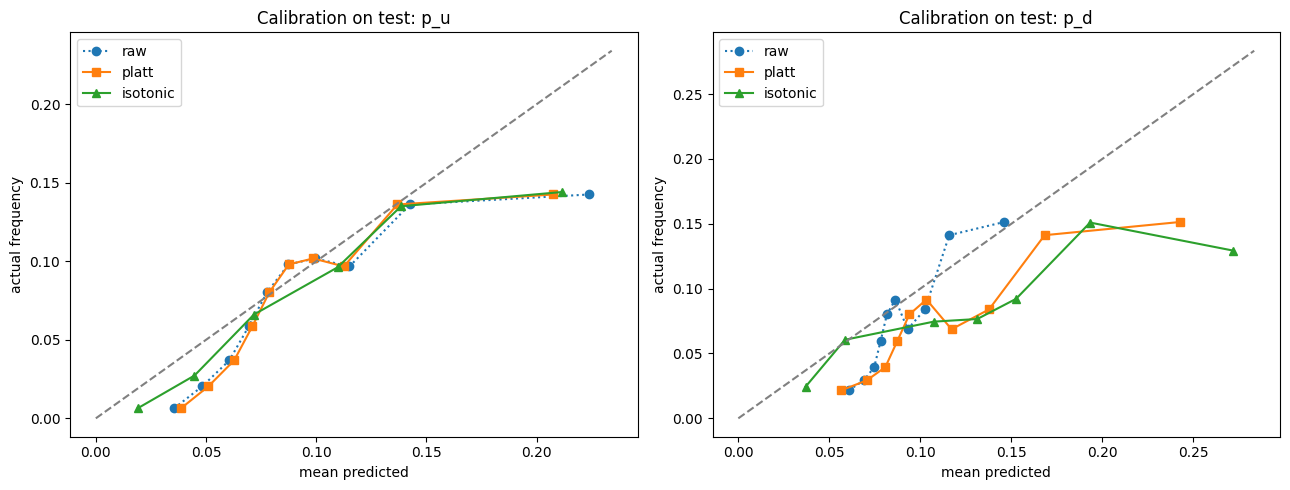

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, side, color in [(axes[0], "u", "blue"), (axes[1], "d", "red")]:
    y = p_test_df[f"yc_test_{side}"]
    for col, style in [(f"p_test_{side}", "o:"), (f"p_test_{side}_platt", "s-"), (f"p_test_{side}_isotonic", "^-")]:
        fp, mp = calibration_curve(y, p_test_df[col], n_bins=10, strategy="quantile")
        ax.plot(mp, fp, style, label=col.replace(f"p_test_{side}", "raw").replace("raw_", ""))
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, lim], [0, lim], "--", color="gray")
    ax.set(title=f"Calibration on test: p_{side}", xlabel="mean predicted", ylabel="actual frequency")
    ax.legend()
plt.tight_layout()
plt.show()

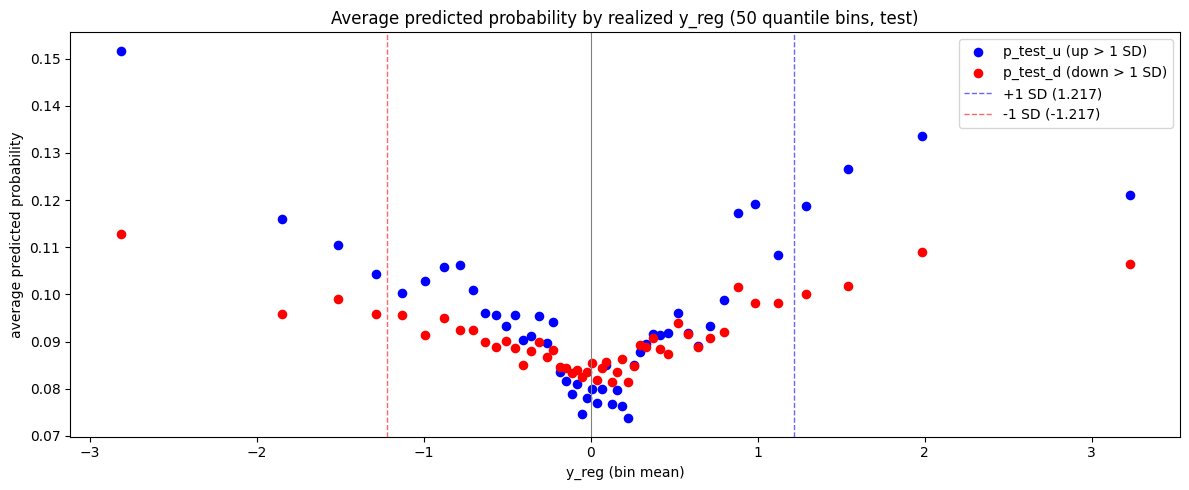

,y_mid,p_u,p_d,n
bin,,,,
"(-5.847, -2.146]",-2.813965,0.151699,0.112749,158
"(-2.146, -1.648]",-1.850590,0.115951,0.095806,157
"(-1.648, -1.391]",-1.512120,0.110393,0.099080,157
"(-1.391, -1.193]",-1.283360,0.104265,0.095931,157
"(-1.193, -1.059]",-1.132149,0.100359,0.095566,157
"(-1.059, -0.934]",-0.993600,0.102900,0.091447,158
"(-0.934, -0.831]",-0.879420,0.105727,0.094902,157
"(-0.831, -0.743]",-0.783244,0.106223,0.092367,157
"(-0.743, -0.665]",-0.705660,0.101022,0.092388,157


In [20]:
N_BINS = 50

df = p_test_df[["y_reg", "p_test_u", "p_test_d"]].dropna().copy()

# Quantile bins keep the count per bin roughly equal, which matters with fat tails
df["bin"] = pd.qcut(df["y_reg"], q=N_BINS, duplicates="drop")

g = df.groupby("bin", observed=True).agg(
    y_mid=("y_reg", "mean"),
    p_u=("p_test_u", "mean"),
    p_d=("p_test_d", "mean"),
    n=("y_reg", "size"),
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(g["y_mid"], g["p_u"], color="blue", s=35, label="p_test_u (up > 1 SD)")
ax.scatter(g["y_mid"], g["p_d"], color="red",  s=35, label="p_test_d (down > 1 SD)")

ax.axvline(0, color="gray", lw=0.8)
ax.axvline(sd, color="blue", ls="--", lw=1, alpha=0.6, label=f"+1 SD ({sd:.3f})")
ax.axvline(-sd, color="red", ls="--", lw=1, alpha=0.6, label=f"-1 SD ({-sd:.3f})")

ax.set(xlabel="y_reg (bin mean)", ylabel="average predicted probability",
       title=f"Average predicted probability by realized y_reg ({len(g)} quantile bins, test)")
ax.legend()
plt.tight_layout()
plt.show()

g

In [21]:
result_check = pd.DataFrame({"p_test": p_test, "yc_test": yc_test})

In [22]:
# Save both models for run_daily.py (config.ASSETS["BTC"]["model_up" / "model_down"])
import json
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for name, m in [("btc_up", clf), ("btc_down", clf_d)]:
    # keep only the trees up to the early-stopping best iteration
    m.booster_.save_model(str(MODEL_DIR / f"{name}.txt"), num_iteration=m.best_iteration_)

# what the models were trained with, for reference
meta = {
    "horizon_bars": HORIZON,
    "label_threshold_pct": float(sd),          # up: y_reg > +sd, down: y_reg < -sd (train SD)
    "best_iteration": {"btc_up": int(clf.best_iteration_), "btc_down": int(clf_d.best_iteration_)},
    "train_end": str(X_train.index[-1]),
    "features": list(X_train.columns),
}
(MODEL_DIR / "btc_models_meta.json").write_text(json.dumps(meta, indent=2))

# check: reloaded boosters give the same probabilities
for name, m in [("btc_up", clf), ("btc_down", clf_d)]:
    loaded = lgb.Booster(model_file=str(MODEL_DIR / f"{name}.txt"))
    assert np.allclose(loaded.predict(X_test), m.predict_proba(X_test)[:, 1])
    print(f"saved {MODEL_DIR / name}.txt  ({loaded.num_trees()} trees, {len(loaded.feature_name())} features)")

saved ../models/btc_up.txt  (95 trees, 72 features)
saved ../models/btc_down.txt  (30 trees, 72 features)
